In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preparacao dos dados para o K-means

In [5]:
df = pd.read_csv('processed_df.csv')
display(df)

/tmp/ipykernel_2151/120325342.py:1: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('processed_df.csv')


,DT_NOTIFIC,ID_OCUPA_N,SIT_TRAB,LOC_EXPO,ID_MUNICIP,UF_EMP,MUN_EMP,AGENTE_TOX,VIA_1,CIRCUNSTAN,...,LOC_EXPO_DESC,AGENTE_TOX_DESC,VIA_1_DESC,CIRCUNSTAN_DESC,TPEXP_DESC,SIT_TRAB_DESC,CLASSI_FIN_DESC,EVOLUCAO_DESC,IDADE_ANOS,INTERNADO
0,2013-04-27,NaN,99.0,1.0,520110,52.0,520110.0,1.0,1.0,2.0,...,Residência,Medicamento,Digestiva,Acidental,Aguda-única,Ignorado,Confirmado,Cura sem sequela,3.0,0
1,2013-04-27,999994.0,99.0,1.0,261110,26.0,261110.0,7.0,1.0,2.0,...,Residência,Domissanitário,Digestiva,Acidental,Aguda-única,Ignorado,Exposição,Cura sem sequela,2.0,0
2,2013-04-27,NaN,99.0,1.0,311460,31.0,311460.0,1.0,1.0,2.0,...,Residência,Medicamento,Digestiva,Acidental,Aguda-única,Ignorado,Confirmado,Cura sem sequela,4.0,0
3,2013-04-27,NaN,12.0,1.0,520140,52.0,520140.0,7.0,1.0,2.0,...,Residência,Domissanitário,Digestiva,Acidental,Aguda-única,Outros,Exposição,Cura sem sequela,2.0,0
4,2013-04-27,NaN,12.0,1.0,270030,27.0,270030.0,1.0,1.0,10.0,...,Residência,Medicamento,Digestiva,Tentativa de suicídio,Aguda-única,Outros,Confirmado,Cura sem sequela,14.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1193313,2023-10-03,NaN,99.0,1.0,421550,42.0,421550.0,7.0,3.0,1.0,...,Residência,Domissanitário,Cutânea,Uso habitual,Aguda-única,Ignorado,Exposição,Cura sem sequela,30.0,0
1193314,2023-10-03,NaN,2.0,1.0,430790,43.0,430790.0,1.0,1.0,10.0,...,Residência,Medicamento,Digestiva,Tentativa de suicídio,Aguda-única,Empregado sem carteira,Confirmado,Cura sem sequela,27.0,1
1193315,2023-10-03,516110,3.0,1.0,410690,41.0,410690.0,1.0,1.0,10.0,...,Residência,Medicamento,Digestiva,Tentativa de suicídio,Aguda-única,Autônomo/conta própria,Confirmado,Cura sem sequela,35.0,1
1193316,2023-10-03,999992,12.0,1.0,330420,33.0,330420.0,1.0,1.0,10.0,...,Residência,Medicamento,Digestiva,Tentativa de suicídio,Aguda-única,Outros,Confirmado,Cura sem sequela,52.0,1


In [6]:
import pandas as pd
# PASSO 1: Filtrar apenas Agrotóxicos
agrotóxicos_alvo = [
    'Agrotóxico (Uso Agrícola)',
    'Agrotóxico (Uso Doméstico)',
    'Agrotóxico (Saúde Pública)'
]

# Mantém apenas as linhas onde a descrição do agente tóxico está na lista acima
df_fase1 = df[df['AGENTE_TOX_DESC'].isin(agrotóxicos_alvo)].copy()


# PASSO 2: Remover Duplicação (Colunas Redundantes)
# Lista de códigos numéricos ou strings curtas que já possuem a versão detalhada em _DESC
colunas_para_remover = [
    'LOC_EXPO', 'AGENTE_TOX', 'VIA_1', 'CIRCUNSTAN',
    'TPEXP', 'SIT_TRAB', 'CLASSI_FIN', 'EVOLUCAO',
    'CS_SEXO', 'CS_GESTANT', 'CS_RACA', 'CS_ESCOL_N'
]

# O 'errors="ignore"' evita que o código quebre caso você rode a célula duas vezes
# e as colunas já tenham sido apagadas
df_fase1 = df_fase1.drop(columns=colunas_para_remover, errors='ignore')

# PASSO 3: Tratamento da Coluna DT_OBITO
# .notna() retorna True (1) se tiver uma data de óbito preenchida e False (0) se for nulo.
# .astype(int) converte os booleanos para 1 e 0.
df_fase1['DT_OBITO'] = df_fase1['DT_OBITO'].notna().astype(int)


# VERIFICAÇÃO DOS RESULTADOS
print(f"Total de registros originais: {len(df)}")
print(f"Total de registros de agrotóxicos: {len(df_fase1)}")
print(f"\nDistribuição de Óbitos (0 = Não / 1 = Sim):")
print(df_fase1['DT_OBITO'].value_counts())

# Exibe as primeiras linhas para conferência
display(df_fase1.head())

Total de registros originais: 1193318
Total de registros de agrotóxicos: 62215

Distribuição de Óbitos (0 = Não / 1 = Sim):
DT_OBITO
0    60483
1     1732
Name: count, dtype: int64


,DT_NOTIFIC,ID_OCUPA_N,ID_MUNICIP,UF_EMP,MUN_EMP,DOENCA_TRA,NUTEMPO,TPTEMPO,TPATENDE,HOSPITAL,...,LOC_EXPO_DESC,AGENTE_TOX_DESC,VIA_1_DESC,CIRCUNSTAN_DESC,TPEXP_DESC,SIT_TRAB_DESC,CLASSI_FIN_DESC,EVOLUCAO_DESC,IDADE_ANOS,INTERNADO
16,2013-04-27,21210.0,230440,23.0,230765.0,2.0,7.0,1.0,1.0,2.0,...,Residência,Agrotóxico (Uso Agrícola),Digestiva,Tentativa de suicídio,Aguda-única,Servidor público estatutário,Confirmado,Cura sem sequela,50.0,0
34,2013-04-27,NaN,411520,41.0,410170.0,2.0,1.0,1.0,1.0,2.0,...,Residência,Agrotóxico (Uso Doméstico),Digestiva,Tentativa de suicídio,Aguda-única,Ignorado,Confirmado,Perda de seguimento,12.0,0
48,2013-04-28,NaN,110004,11.0,110150.0,2.0,1.0,1.0,1.0,1.0,...,Residência,Agrotóxico (Uso Agrícola),Digestiva,Acidental,Aguda-única,Outros,Exposição,Cura sem sequela,1.0,1
52,2013-04-28,621005.0,320140,32.0,320140.0,2.0,5.0,1.0,1.0,1.0,...,Unidade de saúde,Agrotóxico (Uso Agrícola),Digestiva,Tentativa de suicídio,Aguda-repetida,Autônomo/conta própria,Confirmado,Cura sem sequela,29.0,1
77,2013-04-28,999991.0,411150,41.0,412250.0,2.0,1.0,1.0,1.0,1.0,...,Residência,Agrotóxico (Uso Agrícola),Parenteral,Tentativa de suicídio,Aguda-única,Ignorado,Confirmado,Cura sem sequela,17.0,1


In [7]:
import pandas as pd
import numpy as np

# Criamos uma cópia do DataFrame da Fase 1
df_fase2 = df_fase1.copy()

# PASSO 4: Conversão e Unificação de Tempo
# Baseado no Dicionário SINAN (Campo 58):
# 1-Hora | 2-Dia | 3-Mês | 4-Ano | 9-Ignorado

def converter_para_horas(linha):
    nu = linha['NUTEMPO']
    tp = linha['TPTEMPO']

    # Se for nulo, zero, ou código 9 (Ignorado), retornamos NaN
    if pd.isna(nu) or pd.isna(tp) or nu == 0 or tp == 9:
        return np.nan

    if tp == 1:
        return nu               # Já está em horas
    elif tp == 2:
        return nu * 24          # Dias para horas
    elif tp == 3:
        return nu * 24 * 30     # Meses para horas (aproximado, padrão comercial de 30 dias)
    elif tp == 4:
        return nu * 24 * 365    # Anos para horas
    else:
        return np.nan           # Qualquer outro código fora do padrão

# Aplica a função linha a linha
df_fase2['TEMPO_EXPOSICAO_HORAS'] = df_fase2.apply(converter_para_horas, axis=1)

# PASSO 5: Extração de Sazonalidade (Datas)

# Converte a string da data para o tipo 'datetime' do Pandas
df_fase2['DT_NOTIFIC'] = pd.to_datetime(df_fase2['DT_NOTIFIC'], format='%Y-%m-%d', errors='coerce')

# Extrai o mês (1 a 12) para capturar sazonalidade de safras agrícolas
df_fase2['MES_NOTIFICACAO'] = df_fase2['DT_NOTIFIC'].dt.month

# LIMPEZA FINAL DA FASE 2
# Removemos as colunas originais de tempo e a string de data completa
colunas_para_descartar = ['NUTEMPO', 'TPTEMPO', 'DT_NOTIFIC']
df_fase2 = df_fase2.drop(columns=colunas_para_descartar, errors='ignore')
# VERIFICAÇÃO
print("Amostra da conversão de Tempo:")
display(df_fase2[['TEMPO_EXPOSICAO_HORAS', 'MES_NOTIFICACAO']].head(10))

Amostra da conversão de Tempo:


,TEMPO_EXPOSICAO_HORAS,MES_NOTIFICACAO
16,7.0,4
34,1.0,4
48,1.0,4
52,5.0,4
77,1.0,4
118,NaN,4
181,1.0,4
192,NaN,4
195,NaN,4
209,7.0,4


In [8]:
df_fase2

,ID_OCUPA_N,ID_MUNICIP,UF_EMP,MUN_EMP,DOENCA_TRA,TPATENDE,HOSPITAL,DT_OBITO,NU_IDADE_N,CS_SEXO_DESC,...,VIA_1_DESC,CIRCUNSTAN_DESC,TPEXP_DESC,SIT_TRAB_DESC,CLASSI_FIN_DESC,EVOLUCAO_DESC,IDADE_ANOS,INTERNADO,TEMPO_EXPOSICAO_HORAS,MES_NOTIFICACAO
16,21210.0,230440,23.0,230765.0,2.0,1.0,2.0,0,4050,Masculino,...,Digestiva,Tentativa de suicídio,Aguda-única,Servidor público estatutário,Confirmado,Cura sem sequela,50.0,0,7.0,4
34,NaN,411520,41.0,410170.0,2.0,1.0,2.0,0,4012,Masculino,...,Digestiva,Tentativa de suicídio,Aguda-única,Ignorado,Confirmado,Perda de seguimento,12.0,0,1.0,4
48,NaN,110004,11.0,110150.0,2.0,1.0,1.0,0,4001,Feminino,...,Digestiva,Acidental,Aguda-única,Outros,Exposição,Cura sem sequela,1.0,1,1.0,4
52,621005.0,320140,32.0,320140.0,2.0,1.0,1.0,0,4029,Masculino,...,Digestiva,Tentativa de suicídio,Aguda-repetida,Autônomo/conta própria,Confirmado,Cura sem sequela,29.0,1,5.0,4
77,999991.0,411150,41.0,412250.0,2.0,1.0,1.0,0,4017,Feminino,...,Parenteral,Tentativa de suicídio,Aguda-única,Ignorado,Confirmado,Cura sem sequela,17.0,1,1.0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1193198,999992,521975,52.0,521975.0,2.0,1.0,2.0,0,4003,Feminino,...,Digestiva,Acidental,Aguda-única,Ignorado,Exposição,Cura sem sequela,3.0,0,1.0,10
1193223,752305,420940,42.0,420940.0,2.0,1.0,2.0,0,4064,Masculino,...,Digestiva,Acidental,Aguda-única,Aposentado,Diagnóstico Diferencial,Cura sem sequela,64.0,0,1.0,10
1193273,621005,230330,23.0,230330.0,2.0,1.0,1.0,0,4054,Masculino,...,Digestiva,Tentativa de suicídio,Aguda-única,Autônomo/conta própria,Confirmado,Cura sem sequela,54.0,1,2.0,10
1193274,612005,230423,23.0,230423.0,1.0,1.0,2.0,0,4029,Masculino,...,Digestiva,Uso habitual,Aguda-repetida,Empregado sem carteira,Exposição,Cura sem sequela,29.0,0,4.0,10


In [9]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# Criamos a cópia da fase 2
df_fase3_enxuta = df_fase2.copy()

# 1. ENGENHARIA DE ATRIBUTOS

# Ocupação: Em vez de várias categorias, criamos uma flag binária
# Se o código CBO (ID_OCUPA_N) começa com 6, é trabalhador agropecuário
df_fase3_enxuta['ID_OCUPA_N'] = df_fase3_enxuta['ID_OCUPA_N'].fillna('0').astype(str)
df_fase3_enxuta['TRABALHADOR_RURAL'] = df_fase3_enxuta['ID_OCUPA_N'].apply(lambda x: 1 if x.startswith('6') else 0)

# 2. SELEÇÃO ESTRITA DE VARIÁVEIS (REMOVENDO O RUÍDO)

# Vamos manter APENAS o que define o perfil clínico, temporal e a via de exposição.
# Municípios, Raça, Escolaridade e Gestante ficam de fora para o K-Means não se confundir.
colunas_para_manter = [
    'IDADE_ANOS', 'TEMPO_EXPOSICAO_HORAS', 'MES_NOTIFICACAO', # Contínuas/Sazonais
    'DT_OBITO', 'INTERNADO', 'TRABALHADOR_RURAL',             # Binárias diretas
    'CS_SEXO', 'AGENTE_TOX_DESC', 'VIA_1_DESC',               # Categóricas Clínicas Essenciais
    'CIRCUNSTAN_DESC', 'EVOLUCAO_DESC'
]

# Filtramos o DataFrame apenas com as colunas essenciais (ignorando erros se alguma já não existir)
colunas_existentes = [col for col in colunas_para_manter if col in df_fase3_enxuta.columns]
df_filtrado = df_fase3_enxuta[colunas_existentes].copy()

# 3. ONE-HOT ENCODING (DUMMIES)

colunas_categoricas = df_filtrado.select_dtypes(include=['object']).columns

# O drop_first=True continua aqui para evitar multicolinearidade
df_codificado = pd.get_dummies(df_filtrado, columns=colunas_categoricas, drop_first=True)


# 4. ESCALONAMENTO (SCALING)

# Preenchemos nulos contínuos restantes com a mediana
df_codificado = df_codificado.fillna(df_codificado.median())

scaler = StandardScaler()
df_matriz_otimizada = pd.DataFrame(
    scaler.fit_transform(df_codificado),
    columns=df_codificado.columns,
    index=df_codificado.index
)


# VERIFICAÇÃO FINAL
print(f"Colunas reduzidas! Novo total para o modelo: {df_matriz_otimizada.shape[1]}")
display(df_matriz_otimizada.head())

Colunas reduzidas! Novo total para o modelo: 33


,IDADE_ANOS,TEMPO_EXPOSICAO_HORAS,MES_NOTIFICACAO,DT_OBITO,INTERNADO,TRABALHADOR_RURAL,AGENTE_TOX_DESC_Agrotóxico (Uso Agrícola),AGENTE_TOX_DESC_Agrotóxico (Uso Doméstico),VIA_1_DESC_Digestiva,VIA_1_DESC_Ignorado,...,CIRCUNSTAN_DESC_Tentativa de suicídio,CIRCUNSTAN_DESC_Uso habitual,CIRCUNSTAN_DESC_Uso ocupacional,CIRCUNSTAN_DESC_Uso terapêutico,CIRCUNSTAN_DESC_Violência / Homicídio,EVOLUCAO_DESC_Cura sem sequela,EVOLUCAO_DESC_Ignorado,EVOLUCAO_DESC_Perda de seguimento,EVOLUCAO_DESC_Óbito por Intoxicação Exógena,EVOLUCAO_DESC_Óbito por outras causas
16,0.940974,-0.072165,-0.649087,-0.169222,-0.674296,-0.608212,0.668879,-0.608857,0.927000,-0.079628,...,1.372563,-0.39255,-0.084685,-0.026904,-0.030547,0.396984,-0.271494,-0.141309,-0.16654,-0.052652
34,-1.135737,-0.072661,-0.649087,-0.169222,-0.674296,-0.608212,-1.495039,1.642422,0.927000,-0.079628,...,1.372563,-0.39255,-0.084685,-0.026904,-0.030547,-2.518995,-0.271494,7.076697,-0.16654,-0.052652
48,-1.736890,-0.072661,-0.649087,-0.169222,1.483028,-0.608212,0.668879,-0.608857,0.927000,-0.079628,...,-0.728564,-0.39255,-0.084685,-0.026904,-0.030547,0.396984,-0.271494,-0.141309,-0.16654,-0.052652
52,-0.206682,-0.072330,-0.649087,-0.169222,1.483028,1.644164,0.668879,-0.608857,0.927000,-0.079628,...,1.372563,-0.39255,-0.084685,-0.026904,-0.030547,0.396984,-0.271494,-0.141309,-0.16654,-0.052652
77,-0.862486,-0.072661,-0.649087,-0.169222,1.483028,-0.608212,0.668879,-0.608857,-1.078749,-0.079628,...,1.372563,-0.39255,-0.084685,-0.026904,-0.030547,0.396984,-0.271494,-0.141309,-0.16654,-0.052652


# Encontrando melhores valores para o K-means

Calculando Métricas do K-Means (Isso pode levar alguns segundos)...


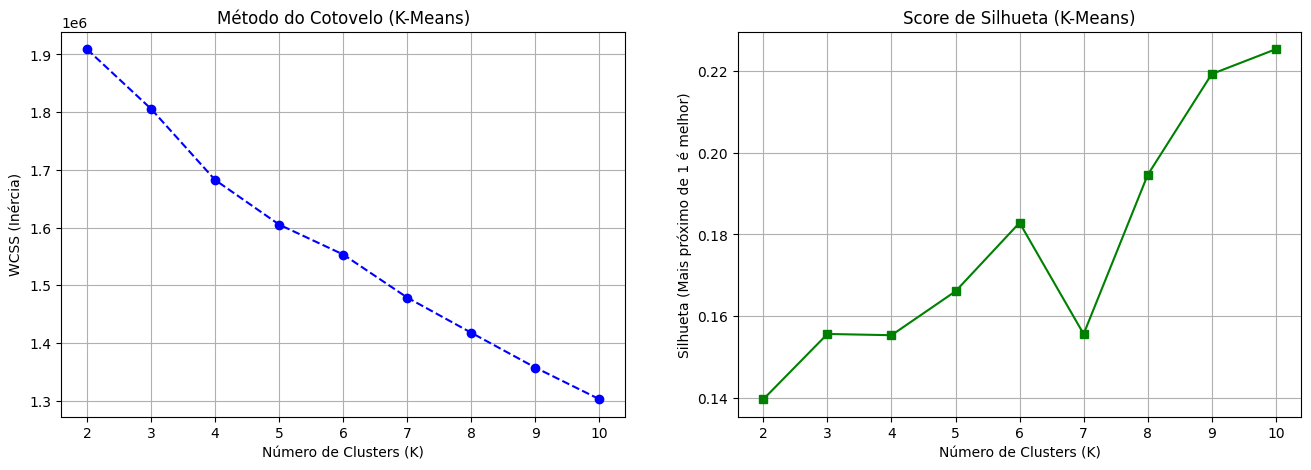

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

# ==========================================
# 1. K-MEANS: Cotovelo e Silhueta
# ==========================================
print("Calculando Métricas do K-Means (Isso pode levar alguns segundos)...")

wcss = []
silhuetas = []
k_range = range(2, 11) # Testando de 2 a 10 grupos

for k in k_range:
    # init='k-means++' é a nossa garantia de boa inicialização
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = kmeans.fit_predict(df_matriz_otimizada)

    # Inércia é a soma dos quadrados das distâncias dentro do cluster (WCSS)
    wcss.append(kmeans.inertia_)

    # Silhueta mede a qualidade da separação
    silhuetas.append(silhouette_score(df_matriz_otimizada, labels))

# Plotando Cotovelo e Silhueta lado a lado
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

ax1.plot(k_range, wcss, marker='o', linestyle='--', color='b')
ax1.set_title('Método do Cotovelo (K-Means)')
ax1.set_xlabel('Número de Clusters (K)')
ax1.set_ylabel('WCSS (Inércia)')
ax1.grid(True)

ax2.plot(k_range, silhuetas, marker='s', linestyle='-', color='g')
ax2.set_title('Score de Silhueta (K-Means)')
ax2.set_xlabel('Número de Clusters (K)')
ax2.set_ylabel('Silhueta (Mais próximo de 1 é melhor)')
ax2.grid(True)

plt.show()


# Analise dos Clusters

In [11]:
# 1. Treinando o K-Means com o melhor K intermediário (ex: 6)
kmeans_final = KMeans(n_clusters=6, init='k-means++', random_state=42, n_init=10)
df_filtrado['CLUSTER_KMEANS'] = kmeans_final.fit_predict(df_matriz_otimizada)

# 2. Perfilando os Clusters (A "Mágica" da Análise)
# Agrupamos pelo cluster e tiramos a média das variáveis numéricas
perfil_numerico = df_filtrado.groupby('CLUSTER_KMEANS')[['IDADE_ANOS', 'TEMPO_EXPOSICAO_HORAS']].mean()

# Somamos as variáveis binárias para ver a concentração (ex: % de óbitos no grupo)
perfil_binario = df_filtrado.groupby('CLUSTER_KMEANS')[['DT_OBITO', 'INTERNADO', 'TRABALHADOR_RURAL']].mean() * 100

print("=== PERFIL MÉDIO DOS PACIENTES POR CLUSTER ===")
display(pd.concat([perfil_numerico, perfil_binario], axis=1).round(2))

# 3. Analisando as Vias de Exposição predominantes em cada grupo
print("\n=== VIA DE EXPOSIÇÃO MAIS COMUM POR CLUSTER ===")
for i in range(6):
    via_comum = df_filtrado[df_filtrado['CLUSTER_KMEANS'] == i]['VIA_1_DESC'].mode()[0]
    print(f"Cluster {i}: {via_comum}")

=== PERFIL MÉDIO DOS PACIENTES POR CLUSTER ===


,IDADE_ANOS,TEMPO_EXPOSICAO_HORAS,DT_OBITO,INTERNADO,TRABALHADOR_RURAL
CLUSTER_KMEANS,,,,,
0,33.87,383.61,0.00,19.26,39.65
1,33.92,154.16,0.00,54.43,17.52
2,28.44,16.08,0.72,42.45,10.07
3,38.48,6474.74,0.00,15.03,57.24
4,26.17,145.29,0.00,27.25,4.27
5,43.45,649.46,94.33,78.26,28.56



=== VIA DE EXPOSIÇÃO MAIS COMUM POR CLUSTER ===
Cluster 0: Cutânea
Cluster 1: Digestiva
Cluster 2: Digestiva
Cluster 3: Cutânea
Cluster 4: Digestiva
Cluster 5: Digestiva


=== 1. PERFIL NUMÉRICO E BINÁRIO (%) ===


,IDADE_ANOS,TEMPO_EXPOSICAO_HORAS,DT_OBITO,INTERNADO,TRABALHADOR_RURAL
CLUSTER_KMEANS,,,,,
0,33.87,383.61,0.00,19.26,39.65
1,33.92,154.16,0.00,54.43,17.52
2,28.44,16.08,0.72,42.45,10.07
3,38.48,6474.74,0.00,15.03,57.24
4,26.17,145.29,0.00,27.25,4.27
5,43.45,649.46,94.33,78.26,28.56



=== 2. DISTRIBUIÇÃO DAS VARIÁVEIS CATEGÓRICAS POR CLUSTER (%) ===

--- Detalhamento: CIRCUNSTAN_DESC ---


CIRCUNSTAN_DESC,Abuso,Acidental,Ambiental,Automedicação,Erro de administração,Ignorado,Ingestão de alimento,Outra,Prescrição médica inadequada,Tentativa de suicídio,Uso habitual,Uso ocupacional,Uso terapêutico,Violência / Homicídio
CLUSTER_KMEANS,,,,,,,,,,,,,,
0,0.1,71.5,16.9,0.0,2.8,2.7,0.1,5.5,0.0,0.1,0.0,0.0,0.1,0.0
1,0.2,0.9,0.0,0.0,0.0,0.9,1.1,0.1,0.0,94.6,0.0,1.9,0.0,0.2
2,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.1,0.0,0.0,0.0,0.0,0.1,0.0,0.0,99.8,0.0,0.0,0.0
4,0.5,52.9,4.1,0.0,1.4,2.2,0.7,2.1,0.0,34.3,0.8,0.7,0.1,0.1
5,0.1,8.9,0.8,0.0,0.4,1.4,0.6,1.7,0.1,81.6,2.7,1.6,0.0,0.2



--- Detalhamento: EVOLUCAO_DESC ---


EVOLUCAO_DESC,Cura com sequela,Cura sem sequela,Ignorado,Perda de seguimento,Óbito por Intoxicação Exógena,Óbito por outras causas
CLUSTER_KMEANS,,,,,,
0,1.7,92.7,4.8,0.7,0.0,0.0
1,2.0,84.0,9.6,4.5,0.0,0.0
2,1.4,87.8,8.6,1.4,0.7,0.0
3,3.5,89.2,6.8,0.5,0.0,0.0
4,1.2,88.9,7.8,2.1,0.0,0.0
5,0.0,0.0,0.0,0.0,90.8,9.2



--- Detalhamento: AGENTE_TOX_DESC ---


AGENTE_TOX_DESC,Agrotóxico (Saúde Pública),Agrotóxico (Uso Agrícola),Agrotóxico (Uso Doméstico)
CLUSTER_KMEANS,,,
0,6.1,93.8,0.1
1,1.9,98.0,0.0
2,5.0,47.5,47.5
3,7.0,82.6,10.4
4,1.5,0.0,98.5
5,1.0,89.2,9.9



--- Detalhamento: VIA_1_DESC ---


VIA_1_DESC,Cutânea,Digestiva,Ignorado,Ocular,Outras,Parenteral,Placentária,Respiratória
CLUSTER_KMEANS,,,,,,,,
0,49.6,21.6,0.9,4.4,0.0,0.1,0.0,23.4
1,0.4,99.0,0.2,0.0,0.0,0.2,0.0,0.2
2,5.8,80.6,0.0,0.0,0.0,0.0,0.0,13.7
3,52.3,10.5,0.7,2.5,0.0,0.1,0.0,33.8
4,21.2,69.6,0.7,1.4,0.0,0.2,0.0,7.0
5,5.3,90.9,1.1,0.1,0.0,0.2,0.0,2.4


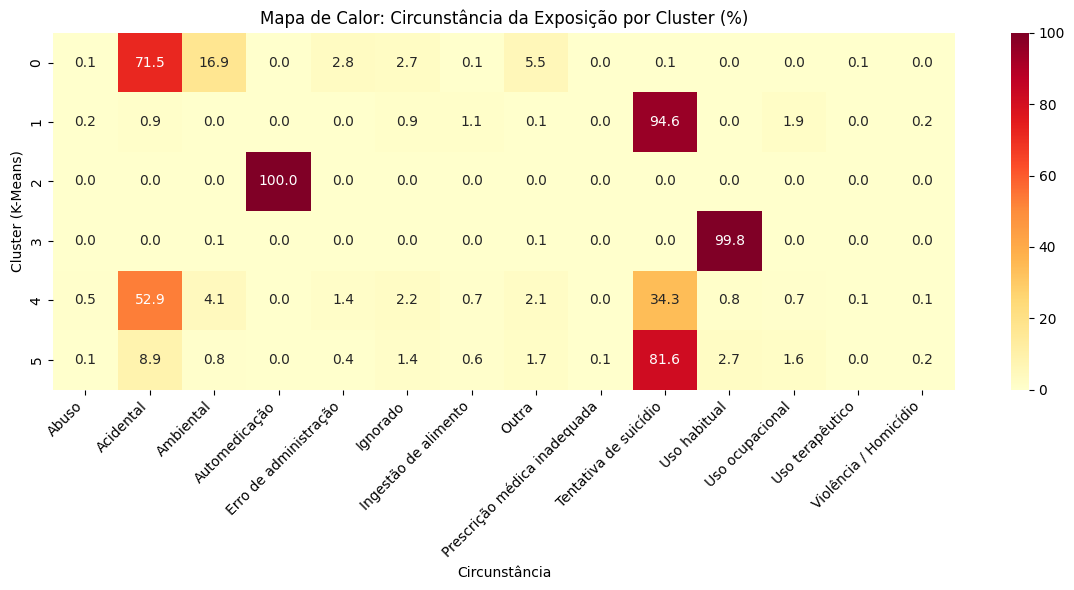

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. VISÃO QUANTITATIVA (Médias e Porcentagens Binárias)
print("=== 1. PERFIL NUMÉRICO E BINÁRIO (%) ===")
resumo_quantitativo = df_filtrado.groupby('CLUSTER_KMEANS')[
    ['IDADE_ANOS', 'TEMPO_EXPOSICAO_HORAS', 'DT_OBITO', 'INTERNADO', 'TRABALHADOR_RURAL']
].mean()

# Multiplicando as variáveis binárias por 100 para facilitar a leitura em %
for col in ['DT_OBITO', 'INTERNADO', 'TRABALHADOR_RURAL']:
    resumo_quantitativo[col] = resumo_quantitativo[col] * 100

display(resumo_quantitativo.round(2))

# 2. VISÃO CATEGÓRICA COMPLETA (O "Raio-X")
# Lista de todas as variáveis de texto que queremos investigar
colunas_categoricas = [
    'CIRCUNSTAN_DESC',
    'EVOLUCAO_DESC',
    'AGENTE_TOX_DESC',
    'VIA_1_DESC',

]

print("\n=== 2. DISTRIBUIÇÃO DAS VARIÁVEIS CATEGÓRICAS POR CLUSTER (%) ===")
for col in colunas_categoricas:
    print(f"\n--- Detalhamento: {col} ---")

    # O normalize='index' faz com que a soma de cada linha (cluster) dê 100%
    tabela_cruzada = pd.crosstab(df_filtrado['CLUSTER_KMEANS'], df_filtrado[col], normalize='index') * 100

    # Exibe a tabela arredondada
    display(tabela_cruzada.round(1))

# 3. BÔNUS VISUAL: Heatmap da Circunstância
# Como a Circunstância dita a gravidade, um mapa de calor ajuda a enxergar os padrões instantaneamente
plt.figure(figsize=(12, 6))
tabela_circunstancia = pd.crosstab(df_filtrado['CLUSTER_KMEANS'], df_filtrado['CIRCUNSTAN_DESC'], normalize='index') * 100

sns.heatmap(tabela_circunstancia, annot=True, cmap="YlOrRd", fmt=".1f")
plt.title("Mapa de Calor: Circunstância da Exposição por Cluster (%)")
plt.ylabel("Cluster (K-Means)")
plt.xlabel("Circunstância")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Aplicando indice do Moran

In [13]:
!pip install geopandas libpysal esda splot geobr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 338.0/338.0 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 34.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 54.0 MB/s eta 0:00:00
  Attempting uninstall: shapely
    Found existing installation: shapely 2.1.2
    Uninstalling shapely-2.1.2:
      Successfully uninstalled shapely-2.1.2
  Attempting uninstall: lxml
    Found existing installation: lxml 6.1.1
    Uninstalling lxml-6.1.1:
      Successfully uninstalled lxml-6.1.1
  Attempting uninstall: geopandas
    Found existing installation: geopandas 1.1.3
    Uninstalling geopandas-1.1.3:
      Successfully uninstalled geopandas-1.1.3


1. Agregando casos do SINAN...
2. Consultando a API do IBGE (População Nacional)...
3. Baixando malha municipal do Brasil (Isso pode demorar um pouco)...
4. Cruzando mapa, casos e população...
5. Calculando Autocorrelação Espacial (Moran)... Aguarde...
('WARNING: ', 1525, ' is an island (no neighbors)')
('WARNING: ', 3499, ' is an island (no neighbors)')
6. Gerando Mapas...


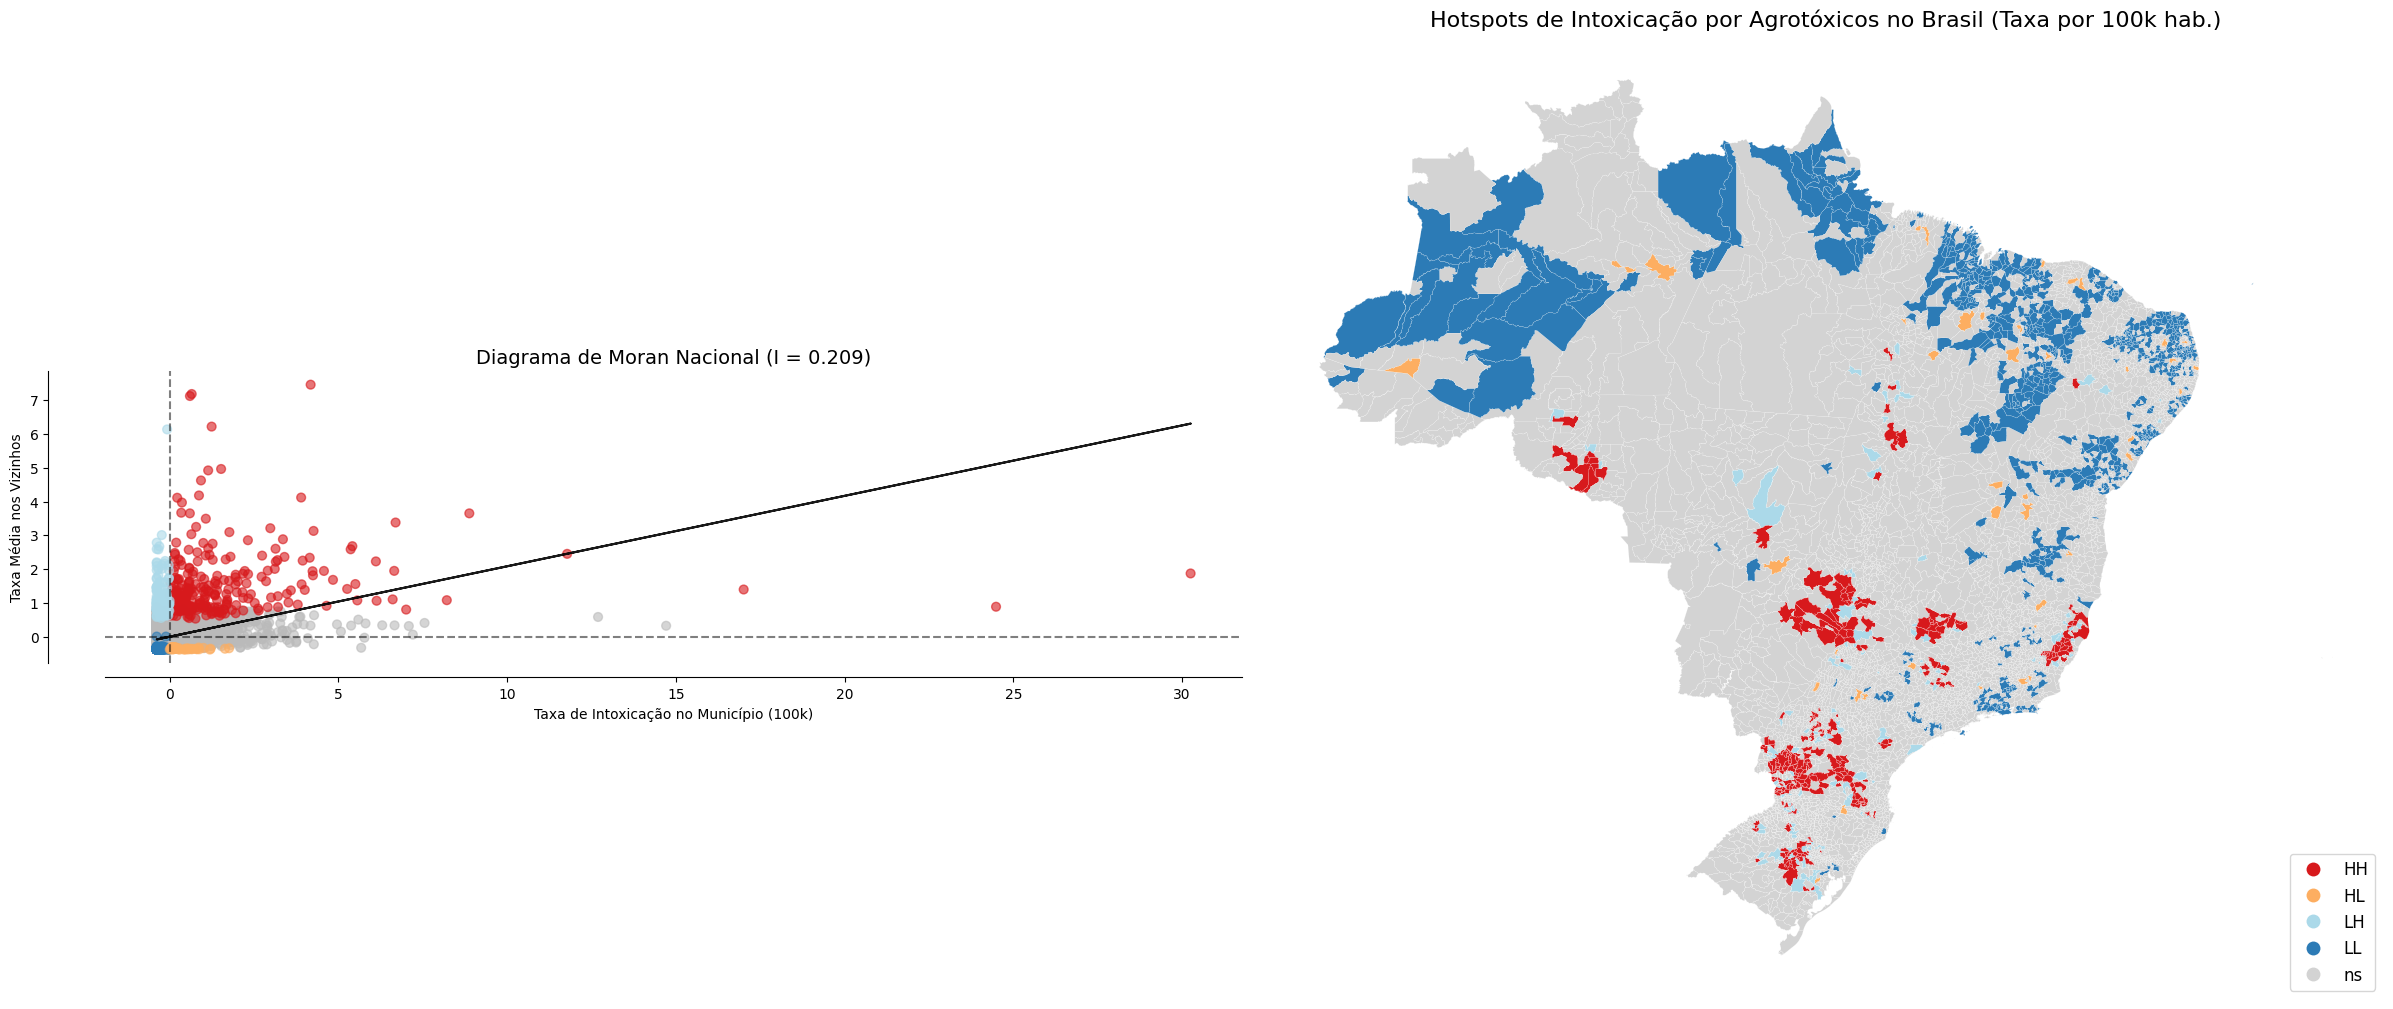

Análise Concluída!


In [14]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import geopandas as gpd
import geobr
from libpysal.weights import Queen
from esda.moran import Moran, Moran_Local
from splot.esda import moran_scatterplot, lisa_cluster
import warnings

# Ignora avisos inofensivos do GeoPandas para manter a tela limpa
warnings.filterwarnings('ignore')

# ==========================================
# 1. AGREGANDO OS DADOS DO SINAN (Nacional)
# ==========================================
print("1. Agregando casos do SINAN...")
casos_por_municipio = df_fase2['ID_MUNICIP'].value_counts().reset_index()
casos_por_municipio.columns = ['ID_MUNICIP', 'TOTAL_CASOS']
casos_por_municipio['ID_MUNICIP'] = casos_por_municipio['ID_MUNICIP'].astype(str).str.split('.').str[0]

# ==========================================
# 2. BUSCANDO POPULAÇÃO NO IBGE (Censo 2022 - Todo o Brasil)
# ==========================================
print("2. Consultando a API do IBGE (População Nacional)...")
url_ibge = "https://servicodados.ibge.gov.br/api/v3/agregados/4709/periodos/2022/variaveis/93?localidades=N6[all]"
response = requests.get(url_ibge)
dados_ibge = response.json()[0]['resultados'][0]['series']

pop_lista = []
for item in dados_ibge:
    cod_ibge = item['localidade']['id'][:6]
    pop = item['serie']['2022']
    populacao = int(pop) if pop.isnumeric() else 0
    pop_lista.append({'ID_MUNICIP': cod_ibge, 'POPULACAO': populacao})

df_populacao = pd.DataFrame(pop_lista)

# ==========================================
# 3. BAIXANDO O MAPA NACIONAL E CRUZANDO DADOS
# ==========================================
print("3. Baixando malha municipal do Brasil (Isso pode demorar um pouco)...")
# Mudança crucial: code_muni="all" traz o Brasil inteiro
mapa_brasil = geobr.read_municipality(code_muni="all", year=2020)
mapa_brasil['code_muni_6'] = mapa_brasil['code_muni'].astype(str).str[:6]

print("4. Cruzando mapa, casos e população...")
mapa_casos = mapa_brasil.merge(casos_por_municipio, left_on='code_muni_6', right_on='ID_MUNICIP', how='left')
mapa_casos['TOTAL_CASOS'] = mapa_casos['TOTAL_CASOS'].fillna(0)
mapa_casos = mapa_casos.merge(df_populacao, left_on='code_muni_6', right_on='ID_MUNICIP', how='left')

# ==========================================
# 4. CÁLCULO DA TAXA POR 100 MIL HABITANTES
# ==========================================
# Removemos cidades sem população registrada para evitar erro matemático
mapa_casos = mapa_casos[mapa_casos['POPULACAO'] > 0].copy()
mapa_casos['TAXA_100K'] = (mapa_casos['TOTAL_CASOS'] / mapa_casos['POPULACAO']) * 100000

# Preenche com 0 eventuais valores nulos na taxa
mapa_casos['TAXA_100K'] = mapa_casos['TAXA_100K'].fillna(0)

# ==========================================
# 5. CÁLCULO DO MORAN E LISA PARA 5.570 CIDADES
# ==========================================
print("5. Calculando Autocorrelação Espacial (Moran)... Aguarde...")
w = Queen.from_dataframe(mapa_casos)
w.transform = 'r'

moran_global = Moran(mapa_casos['TAXA_100K'], w)
moran_local = Moran_Local(mapa_casos['TAXA_100K'], w)

# ==========================================
# 6. PLOTANDO OS RESULTADOS
# ==========================================
print("6. Gerando Mapas...")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(24, 10)) # Aumentei o tamanho do gráfico

# Gráfico 1: Diagrama de Dispersão
moran_scatterplot(moran_local, ax=ax1, p=0.05)
ax1.set_title(f'Diagrama de Moran Nacional (I = {moran_global.I:.3f})', fontsize=14)
ax1.set_xlabel('Taxa de Intoxicação no Município (100k)')
ax1.set_ylabel('Taxa Média nos Vizinhos')

# Gráfico 2: Mapa LISA do Brasil
lisa_cluster(moran_local, mapa_casos, p=0.05, ax=ax2, legend_kwds={'loc': 'lower right', 'fontsize': 12})
ax2.set_title('Hotspots de Intoxicação por Agrotóxicos no Brasil (Taxa por 100k hab.)', fontsize=16)

# Oculta os eixos (latitude/longitude) do mapa para ficar mais limpo
ax2.set_axis_off()

plt.tight_layout()
plt.show()
print("Análise Concluída!")

### 1. O Diagrama de Dispersão (O Índice Global)
Olhe para o título do gráfico à esquerda: I = 0.209.

A Matemática: Em estatística espacial, qualquer valor positivo e significativo de Moran confirma a existência de agrupamentos (clusters). Uma linha de tendência ascendente (aquela linha preta cortando os pontos) significa que o contágio espacial é real: municípios com altas taxas tendem fortemente a ser vizinhos de municípios com altas taxas.

O Significado: O veneno não respeita a fronteira da cidade. A dinâmica agrícola de pulverização, o trânsito de trabalhadores rurais e a contaminação de bacias hidrográficas criam "regiões doentes", e não apenas "cidades doentes".

2. O Mapa de Hotspots (A Epidemiologia em Vermelho)
O mapa à direita (LISA) é o coração do seu projeto. Ele traduz as bolinhas do gráfico em territórios. As manchas vermelhas (High-High) são os verdadeiros "corredores de intoxicação" do Brasil, considerando a proporção de habitantes:

O Cinturão do Sul (PR, SC e RS): É a mancha vermelha mais densa e agressiva do mapa. Aqui ocorre um fenômeno duplo: esta região possui agricultura familiar intensiva combinada com agronegócio de exportação, mas também possui o melhor sistema de vigilância epidemiológica do país. O "viés de notificação" é positivo: eles intoxicam muito, mas também registram muito bem no SINAN.

A Fronteira do MATOPIBA: Repare naquelas manchas vermelhas isoladas mais ao norte (cruzando Maranhão, Tocantins, Piauí e Bahia). Esta é a nova e mais devastadora fronteira de expansão da soja no Brasil. O seu modelo capturou em tempo real o reflexo dessa expansão agrícola na sobrecarga do sistema de saúde local.

O Eixo Centro-Sul (MS, GO, SP, MG): O clássico cinturão da soja, milho e cana-de-açúcar. A mancha desce pelo cerrado e adentra o oeste paulista e o triângulo mineiro.

3. Os Coldspots e as Subnotificações (O Azul)
A Grande Mancha Azul (Low-Low): Cobre quase toda a Bacia Amazônica e partes do sertão nordestino. Nesses locais, as taxas são baixas e os vizinhos também têm taxas baixas.

O Veredito do Azul: Embora a agricultura de precisão e a monocultura intensiva sejam menores nessas áreas (explicando a queda natural das taxas), uma mancha azul tão vasta e uniforme na região Norte é um grito de alerta para subnotificação crônica. Há falta de acesso a hospitais, dificuldade de diagnóstico ou simplesmente a ficha do SINAN não é preenchida nas unidades básicas de saúde fluviais e rurais da Amazônia.

1. Agregando os casos do Cluster 3 (Crônico/Rural) e Cluster 5 (Agudo/Letal)...
2. Baixando malha do Brasil e cruzando com a População...
3. Calculando Matrizes Espaciais (Isso leva cerca de 2 a 3 minutos)...
('WARNING: ', 1525, ' is an island (no neighbors)')
('WARNING: ', 3499, ' is an island (no neighbors)')
4. Gerando a visualização comparativa...


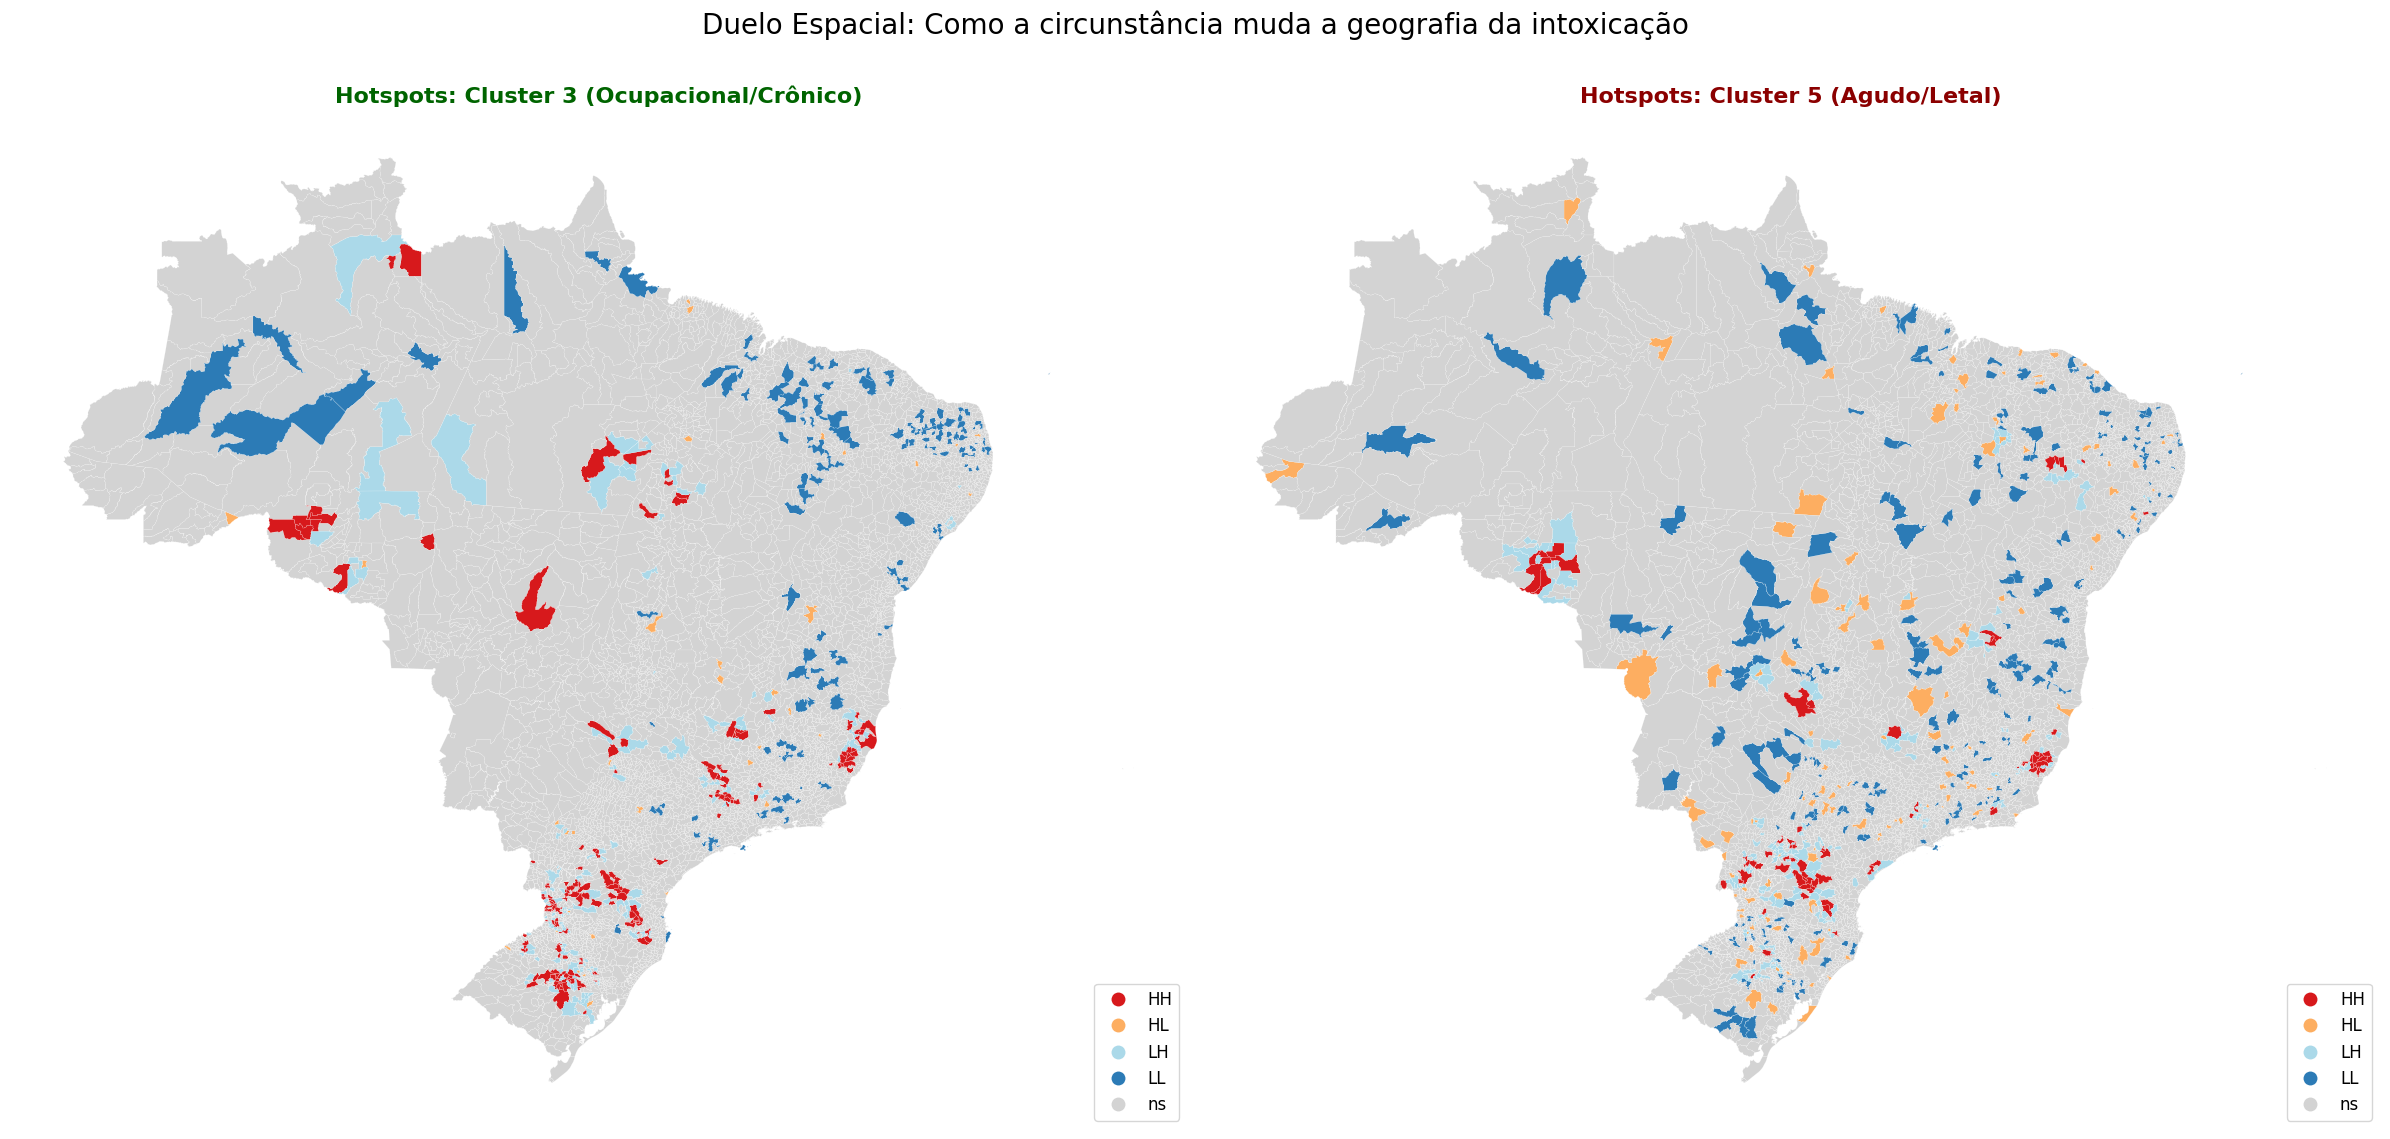

In [15]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import geopandas as gpd
import geobr
from libpysal.weights import Queen
from esda.moran import Moran_Local
from splot.esda import lisa_cluster
import warnings

warnings.filterwarnings('ignore')

# ==========================================
# 1. DEVOLVENDO OS CLUSTERS PARA A BASE COM MAPA
# ==========================================
# Como os DataFrames mantiveram a mesma ordem, podemos simplesmente copiar a coluna
df_fase2['CLUSTER_KMEANS'] = df_filtrado['CLUSTER_KMEANS']

# ==========================================
# 2. FILTRANDO E AGREGANDO POR PERFIL
# ==========================================
print("1. Agregando os casos do Cluster 3 (Crônico/Rural) e Cluster 5 (Agudo/Letal)...")

def agregar_casos(cluster_id):
    casos = df_fase2[df_fase2['CLUSTER_KMEANS'] == cluster_id]['ID_MUNICIP'].value_counts().reset_index()
    casos.columns = ['ID_MUNICIP', 'TOTAL_CASOS']
    casos['ID_MUNICIP'] = casos['ID_MUNICIP'].astype(str).str.split('.').str[0]
    return casos

casos_c3 = agregar_casos(3)
casos_c5 = agregar_casos(5)

# ==========================================
# 3. PREPARANDO O MAPA E A POPULAÇÃO (Otimizado)
# ==========================================
print("2. Baixando malha do Brasil e cruzando com a População...")
# Obs: Assumindo que df_populacao já foi gerado no bloco anterior
mapa_brasil = geobr.read_municipality(code_muni="all", year=2020)
mapa_brasil['code_muni_6'] = mapa_brasil['code_muni'].astype(str).str[:6]

# Função para cruzar casos, população e calcular a Taxa 100k
def preparar_mapa_taxa(casos_df):
    mapa = mapa_brasil.merge(casos_df, left_on='code_muni_6', right_on='ID_MUNICIP', how='left')
    mapa['TOTAL_CASOS'] = mapa['TOTAL_CASOS'].fillna(0)
    mapa = mapa.merge(df_populacao, left_on='code_muni_6', right_on='ID_MUNICIP', how='left')
    mapa = mapa[mapa['POPULACAO'] > 0].copy()
    mapa['TAXA_100K'] = (mapa['TOTAL_CASOS'] / mapa['POPULACAO']) * 100000
    mapa['TAXA_100K'] = mapa['TAXA_100K'].fillna(0)
    return mapa

mapa_c3 = preparar_mapa_taxa(casos_c3)
mapa_c5 = preparar_mapa_taxa(casos_c5)

# ==========================================
# 4. CALCULANDO A AUTOCORRELAÇÃO (LISA)
# ==========================================
print("3. Calculando Matrizes Espaciais (Isso leva cerca de 2 a 3 minutos)...")
# Matriz de vizinhança é a mesma para ambos (o mapa do Brasil)
w = Queen.from_dataframe(mapa_c3)
w.transform = 'r'

moran_local_c3 = Moran_Local(mapa_c3['TAXA_100K'], w)
moran_local_c5 = Moran_Local(mapa_c5['TAXA_100K'], w)

# ==========================================
# 5. PLOTANDO O DUELO DE MAPAS
# ==========================================
print("4. Gerando a visualização comparativa...")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(24, 12))

# Mapa 1: Trabalhador Rural (Cluster 3)
lisa_cluster(moran_local_c3, mapa_c3, p=0.05, ax=ax1, legend_kwds={'loc': 'lower right', 'fontsize': 12})
ax1.set_title('Hotspots: Cluster 3 (Ocupacional/Crônico)', fontsize=16, fontweight='bold', color='darkgreen')
ax1.set_axis_off()

# Mapa 2: Tentativas de Suicídio/Letal (Cluster 5)
lisa_cluster(moran_local_c5, mapa_c5, p=0.05, ax=ax2, legend_kwds={'loc': 'lower right', 'fontsize': 12})
ax2.set_title('Hotspots: Cluster 5 (Agudo/Letal)', fontsize=16, fontweight='bold', color='darkred')
ax2.set_axis_off()

plt.suptitle("Duelo Espacial: Como a circunstância muda a geografia da intoxicação", fontsize=20)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

1. O Mapa Verde (Cluster 3 - A Geografia do Trabalho)
Este é o mapa do agronegócio e da exposição crônica diária.

As Manchas Vermelhas (High-High): Note como elas formam blocos sólidos, "corredores" inteiros. Vemos isso fortemente no Mato Grosso, no interior paulista e descendo para o Sul. Isso comprova o contágio espacial ocupacional: a pulverização, o vento, a contaminação da água e a rotina de trabalho afetam microrregiões inteiras.

O Veredito: Onde a monocultura intensiva dita a economia, o sistema de saúde regional inteiro sofre com o acúmulo de casos crônicos de intoxicação cutânea de baixa letalidade.

2. O Mapa Vermelho (Cluster 5 - A Geografia da Tragédia)
Aqui a dinâmica muda drasticamente (intoxicações agudas e letais, majoritariamente tentativas de suicídio via digestiva).

A Explosão de Pontos Laranjas (High-Low): Repare no Norte, Nordeste e Centro-Oeste. O mapa está salpicado de municípios isolados em laranja. São os outliers espaciais. Isso prova que o suicídio ou o acidente agudo letal não respeita fronteiras agrícolas contínuas na maior parte do país; eles são eventos traumáticos isolados em cidades vulneráveis.

O "Cinturão de Fogo" no Sul: A exceção assustadora é a região Sul (Paraná, Santa Catarina e Rio Grande do Sul). O mapa lá continua profundamente vermelho (High-High) mesmo para o Cluster Letal. Isso cruza perfeitamente com a literatura epidemiológica brasileira: a região Sul, com sua forte tradição de agricultura familiar (como a fumicultura), possui altíssimos índices de suicídio no campo. O endividamento do pequeno produtor, somado à neurotoxicidade crônica dos organofosforados (que induz depressão severa), cria um polo regional de intoxicação letal.